# 05 · Cerebellum: do the treatments reverse aging?
**Question.** Do dietary restriction (**aDR**) and young plasma (**YMP**) push cerebellar expression back towards the young state? **Input:** counts of the three methods (notebook 01). **Output:** `results/aging_vs_rejuvenation/`. **Kernel:** R (`ir`) · **Time:** ~4 min (the first run downloads the MSigDB gene sets).

Everything runs for kallisto, STAR and RSEM through the same DESeq2 code; none is primary yet (notebook 04, section 5). Tables cover all three, figures show the method in `SHOW`. **Aging signal** = 21 vs 3 months; **reversal** = a treatment moves a gene or pathway opposite to aging.

Sections: 2 aging genes · 3 overlap of treatment and aging DEGs, and direction · 4 per-sample aging-signature score (down = rejuvenation) · 5 pathways reversed? · 6 the paper's named genes.

**Caveats:** 3–5 mice per group; treatments at 19 months, aging at 21; aDR female-only, YMP male-only. Scores are z-scored within each treated/control pair, so cohort batch does not enter. P-values are indicative. Terms: [docs/glossary.md](../docs/glossary.md).

## 1 · Setup
`fits` holds, per method, the DESeq2 models (`dds`) and result tables (`res`); SRR21355389 is excluded from aging as in notebook 03.

In [1]:
# counts for the three methods -> DESeq2 models and tables; summary of up / down DEGs per comparison
source('../R/helpers.R')
SHOW <- 'kallisto'   # method drawn in the figures and in the single-method tables; every table with a `method` column covers all three
samples <- load_samples()
x <- load_txi(rownames(samples)); genes <- x$genes
counts <- list(kallisto = x$txi, STAR = load_star_counts()[, rownames(samples)], RSEM = load_rsem(rownames(samples)))
fits <- lapply(counts, \(cn) { d <- run_dds(cn, samples); list(dds = d, res = de_tables(d, genes)) })   # same exclusion of SRR21355389 as notebook 03
bind_rows(lapply(fits, \(f) bind_rows(lapply(f$res, n_deg), .id = 'contrast')), .id = 'method')

method,contrast,up,down
<chr>,<chr>,<int>,<int>
kallisto,aging_18v3,101,25
kallisto,aging_21v3,82,52
kallisto,aDR,64,75
kallisto,YMP,17,24
STAR,aging_18v3,117,32
STAR,aging_21v3,98,70
STAR,aDR,70,115
STAR,YMP,9,17
RSEM,aging_18v3,95,20


## 2 · The aging signature (21 vs 3 months)
The aging DEGs (padj < 0.05), split by direction, are the signature used in analyses 3 and 4.

In [2]:
# numbers of aging-up and aging-down genes per method
sig <- lapply(fits, \(f) { a <- filter(f$res$aging_21v3, padj < 0.05); list(up = a$gene_id[a$log2FoldChange > 0], down = a$gene_id[a$log2FoldChange < 0]) })
tibble(method = names(sig), up = lengths(lapply(sig, `[[`, 'up')), down = lengths(lapply(sig, `[[`, 'down')))

method,up,down
<chr>,<int>,<int>
kallisto,82,52
STAR,98,70
RSEM,74,42


## 3 · Overlap of treatment DEGs with aging DEGs
`shared` vs `expected_by_chance`; `shared_reversal` = opposite to aging (rejuvenating), `shared_same` = like aging; `fisher_p` = overlap beyond chance; `lfc_spearman_agingDEG` = log2FC correlation with aging among aging DEGs (**negative = reversal**).

In [3]:
# overlap statistics per method and treatment
ov <- bind_rows(lapply(names(fits), \(m) bind_rows(lapply(c('aDR', 'YMP'), \(n)
  overlap_with_aging(fits[[m]]$res$aging_21v3, fits[[m]]$res[[n]]) %>% mutate(intervention = n))) %>% mutate(method = m))) %>% relocate(method, intervention)
ov

method,intervention,genes,aging_DEG,intervention_DEG,shared,expected_by_chance,shared_reversal,shared_same,fisher_p,lfc_spearman_all,lfc_spearman_agingDEG
<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>
kallisto,aDR,16474,124,139,6,1.0,0,6,6.4e-04,0.140,0.389
kallisto,YMP,19860,132,40,2,0.3,2,0,2.9e-02,-0.131,-0.476
STAR,aDR,13918,149,185,13,2.0,1,12,9.2e-08,0.169,0.475
STAR,YMP,16122,163,25,3,0.3,3,0,2.0e-03,-0.176,-0.407
RSEM,aDR,12959,108,117,5,1.0,0,5,2.9e-03,0.154,0.438
RSEM,YMP,16603,116,45,2,0.3,2,0,3.9e-02,-0.143,-0.326


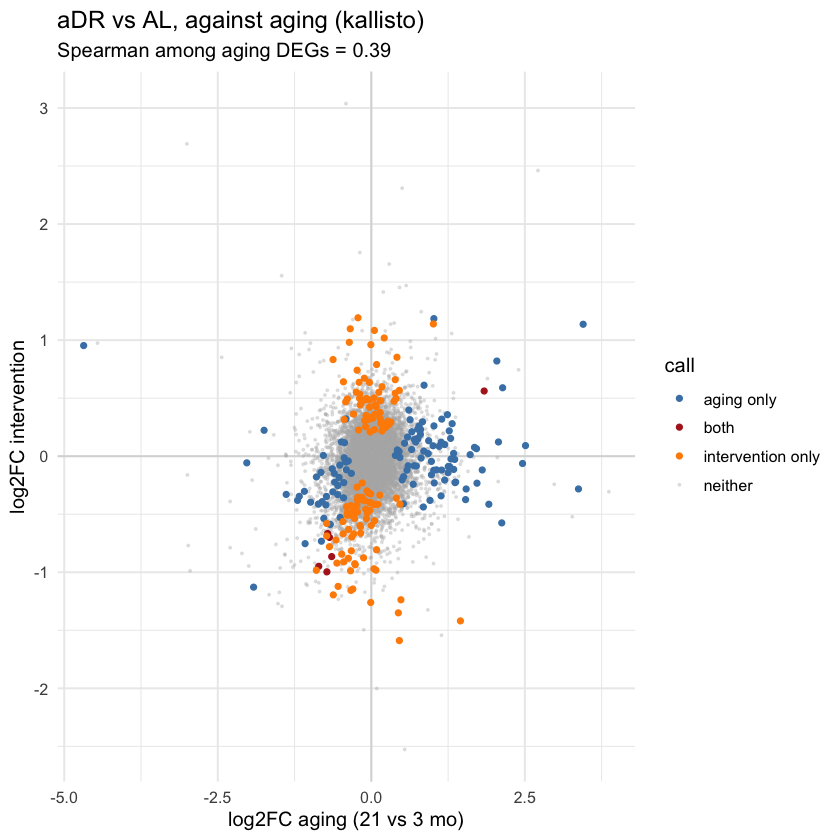

In [4]:
# each dot is a gene: log2FC in aging (x) vs in aDR (y); points on the diagonal move like aging
lfc_vs_aging_plot(fits[[SHOW]]$res$aging_21v3, fits[[SHOW]]$res$aDR, paste0('aDR vs AL, against aging (', SHOW, ')'))

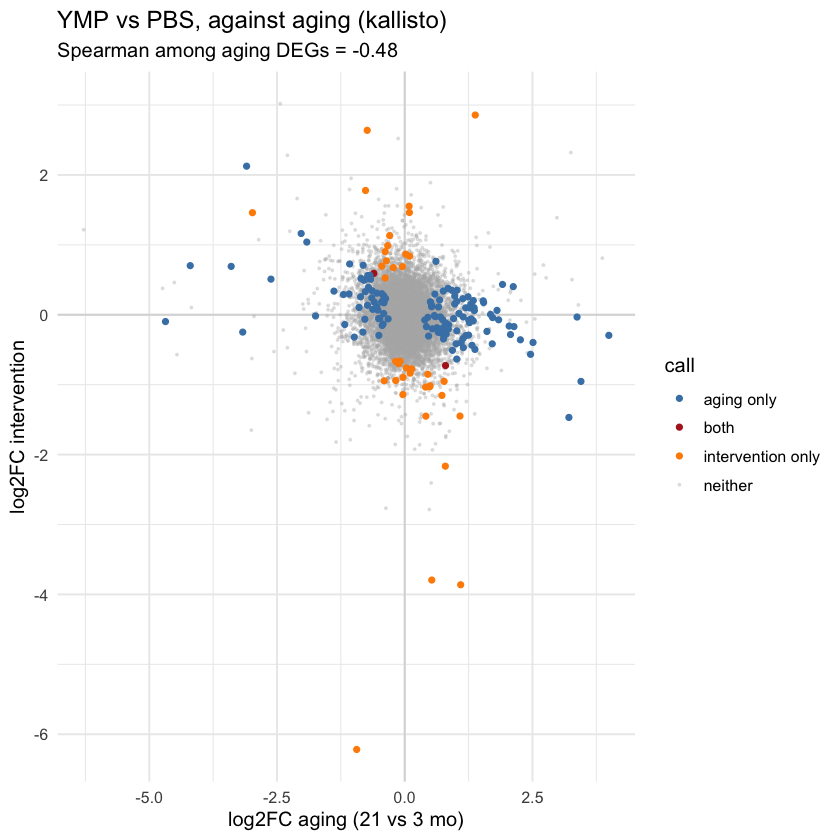

In [5]:
# the same for YMP: points in the upper-left / lower-right quadrants = reversal
lfc_vs_aging_plot(fits[[SHOW]]$res$aging_21v3, fits[[SHOW]]$res$YMP, paste0('YMP vs PBS, against aging (', SHOW, ')'))

## 4 · Aging-signature score per sample
Score = mean z-score of the aging-up genes minus that of the aging-down genes (z-scored within the samples of the same experiment). The *aging* panel is a sanity check (the signature came from these mice); a rejuvenating treatment should **lower** the score relative to its control.

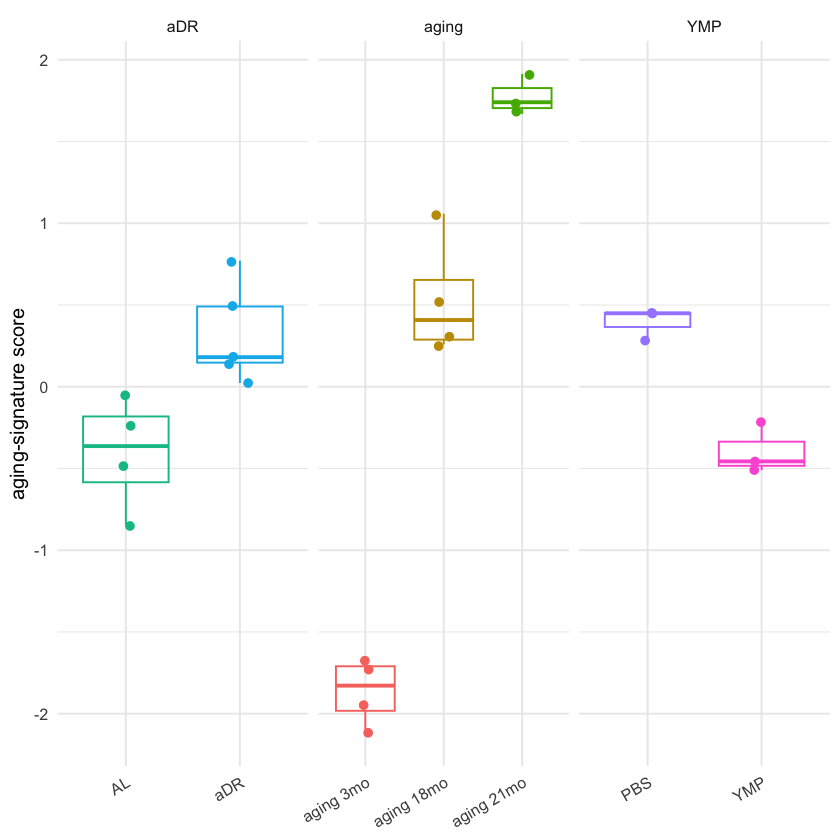

In [6]:
# score per mouse, by group (method SHOW)
scores <- lapply(names(fits), \(m) lapply(fits[[m]]$dds, signature_score, up = sig[[m]]$up, down = sig[[m]]$down)) %>% setNames(names(fits))
score_plot(scores[[SHOW]])

In [7]:
# treated minus control (diff) with a Welch t-test, per method
score_tests <- bind_rows(lapply(names(scores), \(m) bind_rows(score_test(scores[[m]]$aDR, 'aDR', 'AL'), score_test(scores[[m]]$YMP, 'YMP', 'PBS')) %>% mutate(method = m))) %>% relocate(method)
score_tests

method,treated,control,n_t,n_c,diff,t_test_p
<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>
kallisto,aDR,AL,5,4,0.726,0.0160
kallisto,YMP,PBS,3,3,-0.789,0.0035
STAR,aDR,AL,5,4,0.770,0.0180
STAR,YMP,PBS,3,3,-0.730,0.0480
RSEM,aDR,AL,5,4,0.822,0.0110
RSEM,YMP,PBS,3,3,-0.824,0.0430


`diff` < 0 = treated mice lower than control (rejuvenating direction); with 3–5 mice per group the p-values are rough.

## 5 · Pathways (GSEA)
**GSEA** (fgsea) ranks all genes by the Wald statistic and tests whether a gene set sits mainly at the top (up) or bottom (down); **NES** = score (positive = up). Sets: MSigDB's 50 **Hallmark** and ~7,500 **GO biological-process** sets.

In [8]:
# GSEA for aging, aDR and YMP with both gene-set collections, for each method; counts of significant sets
sets <- msigdb_sets()
contrasts <- c('aging_21v3', 'aDR', 'YMP')
gs_h <- lapply(fits, \(f) lapply(f$res[contrasts], run_gsea, sets = sets$hallmark))
gs_go <- lapply(fits, \(f) lapply(f$res[contrasts], run_gsea, sets = sets$gobp))
bind_rows(lapply(names(gs_h), \(m) bind_rows(lapply(names(gs_h[[m]]), \(n) tibble(method = m, contrast = n, hallmark_sig = sum(gs_h[[m]][[n]]$padj < 0.05), gobp_sig = sum(gs_go[[m]][[n]]$padj < 0.05))))))

method,contrast,hallmark_sig,gobp_sig
<chr>,<chr>,<int>,<int>
kallisto,aging_21v3,19,469
kallisto,aDR,23,471
kallisto,YMP,26,207
STAR,aging_21v3,19,414
STAR,aDR,20,619
STAR,YMP,27,297
RSEM,aging_21v3,17,375
RSEM,aDR,17,539
RSEM,YMP,24,208


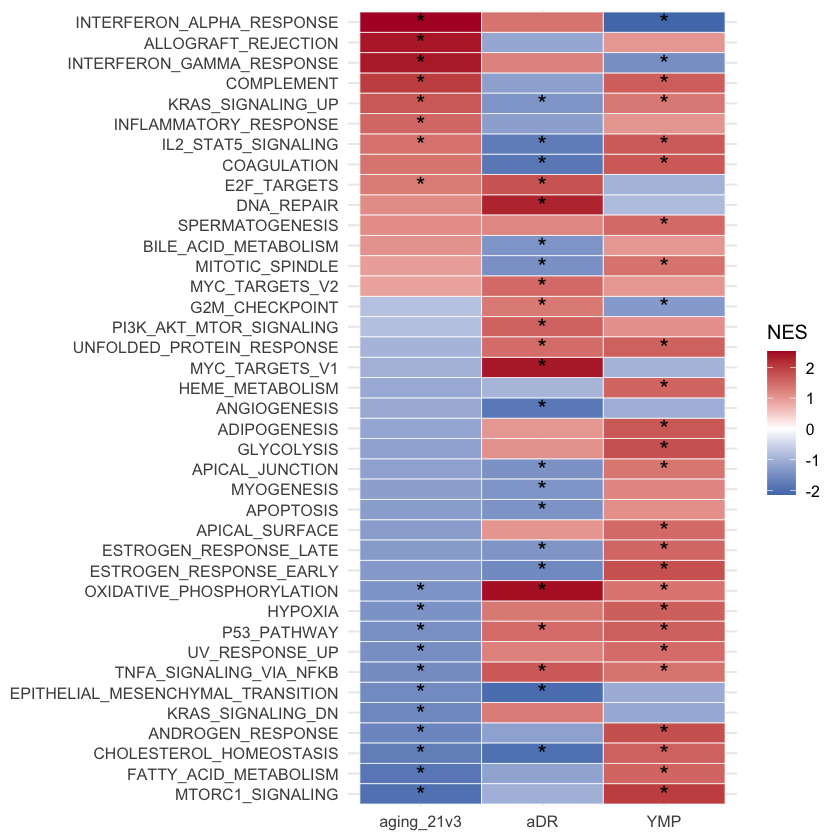

In [9]:
# Hallmark NES for aging vs the treatments (blue = down, red = up, * = padj < 0.05); opposite colours = reversal
nes_tiles(gs_h[[SHOW]])   # blue = down, red = up; * = padj < 0.05. Opposite colours between aging and a treatment = reversal

In [10]:
# of the sets significant in aging: how many does each treatment reverse (opposite NES) or mimic (same sign), both padj < 0.05
bind_rows(Hallmark = bind_rows(lapply(gs_h, gsea_concordance), .id = 'method'), GO_BP = bind_rows(lapply(gs_go, gsea_concordance), .id = 'method'), .id = 'collection')

collection,method,intervention,aging_sets,significant_in_both,reversed,same_direction,NES_spearman_all_sets
<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>
Hallmark,kallisto,aDR,19,8,5,3,0.06
Hallmark,kallisto,YMP,19,14,11,3,-0.35
Hallmark,STAR,aDR,19,7,4,3,0.09
Hallmark,STAR,YMP,19,15,13,2,-0.46
Hallmark,RSEM,aDR,17,7,5,2,0.07
Hallmark,RSEM,YMP,17,11,10,1,-0.47
GO_BP,kallisto,aDR,464,66,26,40,0.11
GO_BP,kallisto,YMP,466,44,35,9,-0.24
GO_BP,STAR,aDR,414,62,25,37,0.18


## 6 · The paper's named gene sets in our cerebellum data
**Aging (CAS, Fig. 2B):** the 26 genes named in the figure; the full 82-gene list is in the paper's Table S1, which we do not have. **aDR (Fig. 6J):** the 23 genes the paper reports as aDR-regulated in at least 4 brain regions (circadian and cycling genes).

In [11]:
# the paper's aging genes: log2FC and padj in aging, aDR and YMP
cas <- c('Gpr17','Hsph1','Dnajb1','Chordc1','P4ha1','Ahsa1','Hist3h2a','C4b','H2-Q6','H2-Q7','Cirbp','Flt1','Tipin','Ctsz','Pcdhb14','Abca8a','Pcdhb8','Pcdhb6','Pcdhb9','H2-K1','Psmb8','Hvcn1','C1qa','Ctss','Tyrobp','Trem2')
adr23 <- c('Chordc1','Cxcl12','Fabp7','Kdr','Adipor2','Gjb6','Mertk','Cry1','Klf15','Dbp','Usp2','Etnppl','Ciart','Sult1a1','Zbtb16','Fkbp5','Sgk1','Tsc22d3','Cirbp','Rbm3','Plin4','Fmo2','Hif3a')
gene_table(fits[[SHOW]]$res, cas) %>% arrange(padj_aging)

symbol,lfc_aging,padj_aging,lfc_aDR,padj_aDR,lfc_YMP,padj_YMP
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
C4b,1.91,9.0e-15,-0.41,0.82000,0.43,0.9800
H2-K1,0.96,4.8e-09,-0.38,0.48000,-0.05,1.0000
Ctss,0.98,4.8e-08,-0.16,0.84000,0.27,0.9400
Tyrobp,1.25,4.2e-06,-0.14,0.91000,-0.29,0.9600
C1qa,1.06,1.7e-05,-0.12,0.94000,0.02,1.0000
H2-Q6,2.12,3.4e-05,-0.57,0.57000,0.40,0.9200
Hsph1,-0.60,1.4e-04,-0.15,0.77000,0.59,0.0031
Trem2,1.36,1.7e-04,-0.03,0.99000,0.10,1.0000
Psmb8,1.27,1.8e-04,0.22,0.88000,-0.11,1.0000


In [12]:
# the paper's aDR genes: how many go up with aDR in our data, and how many are significant
bind_rows(lapply(fits, \(f) { t <- gene_table(f$res, adr23); tibble(genes = nrow(t), up_in_aDR = sum(t$lfc_aDR > 0), significant_aDR = sum(t$padj_aDR < 0.05, na.rm = TRUE)) }), .id = 'method')

method,genes,up_in_aDR,significant_aDR
<chr>,<int>,<int>,<int>
kallisto,23,19,11
STAR,23,19,15
RSEM,23,19,10


## 7 · Save
Small summary tables for the report.

In [13]:
# writes results/aging_vs_rejuvenation/*.csv
dir.create(file.path(ROOT, 'results/aging_vs_rejuvenation'), showWarnings = FALSE)
out <- file.path(ROOT, 'results/aging_vs_rejuvenation')
write_csv(ov, file.path(out, 'overlap_with_aging.csv')); write_csv(score_tests, file.path(out, 'signature_score_tests.csv'))
write_csv(bind_rows(lapply(gs_h, \(g) bind_rows(g, .id = 'contrast')), .id = 'method'), file.path(out, 'gsea_hallmark.csv'))
write_csv(bind_rows(Hallmark = bind_rows(lapply(gs_h, gsea_concordance), .id = 'method'), GO_BP = bind_rows(lapply(gs_go, gsea_concordance), .id = 'method'), .id = 'collection'), file.path(out, 'gsea_concordance.csv'))
write_csv(gene_table(fits[[SHOW]]$res, cas), file.path(out, 'paper_CAS_named_genes.csv'))
list.files(out)

[1] "gsea_concordance.csv"      "gsea_hallmark.csv"        
[3] "overlap_with_aging.csv"    "paper_CAS_named_genes.csv"
[5] "signature_score_tests.csv"